# EPA FUEL ECONOMY 2025

Analisis del dataset...

objetivos ...


In [1]:
import pandas as pd
import numpy as np

## Limpieza del dataset

En _*RAW_DATASET*_ mantendremos el dataset original; mientras que _*PREPROCESSED_DATASET*_ sera limpiado para ser usado en el trabajo.

In [2]:
raw_dataset = pd.read_excel('25-testcar-2026-01-21.xlsx') 
preprocessed_dataset = raw_dataset.copy()

print("Dimensiones iniciales del dataset = [filas, columnas]:", raw_dataset.shape)


pd.options.display.max_columns = None
raw_dataset.head()

Dimensiones iniciales del dataset = [filas, columnas]: (4287, 67)


,Model Year,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,Rated Horsepower,# of Cylinders and Rotors,Engine Code,Tested Transmission Type Code,Tested Transmission Type,# of Gears,Transmission Lockup?,Drive System Code,Drive System Description,Transmission Overdrive Code,Transmission Overdrive Desc,Equivalent Test Weight (lbs.),Axle Ratio,N/V Ratio,Shift Indicator Light Use Cd,Shift Indicator Light Use Desc,Test Number,Test Originator,Analytically Derived FE?,ADFE Test Number,ADFE Total Road Load HP,ADFE Equiv. Test Weight (lbs.),ADFE N/V Ratio,Test Procedure Cd,Test Procedure Description,Test Fuel Type Cd,Test Fuel Type Description,Test Category,THC (g/mi),CO (g/mi),CO2 (g/mi),NOx (g/mi),PM (g/mi),CH4 (g/mi),N2O (g/mi),RND_ADJ_FE,FE_UNIT,FE Bag 1,FE Bag 2,FE Bag 3,FE Bag 4,DT-Inertia Work Ratio Rating,DT-Absolute Speed Change Ratg,DT-Energy Economy Rating,Target Coef A (lbf),Target Coef B (lbf/mph),Target Coef C (lbf/mph**2),Set Coef A (lbf),Set Coef B (lbf/mph),Set Coef C (lbf/mph**2),Aftertreatment Device Cd,Aftertreatment Device Desc,Police - Emergency Vehicle?,Averaging Group ID,Averaging Weighting Factor,Averaging Method Cd,Averging Method Desc
0,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,680,8.0,177850,A,Automatic,8,Y,R,"2-Wheel Drive, Rear",2,Top gear ratio < 1,4500,3.08,24.8,1,Not eqipped,RASX10082337,MFR,No,NaN,NaN,NaN,NaN,21,Federal fuel 2-day exhaust (w/can load),61,Tier 2 Cert Gasoline,FTP,0.0256,0.536,484.329,0.008,NaN,0.0089,0.0039,18.3,MPG,17.8185,17.0058,21.6199,NaN,-0.100,-0.200,-0.350,53.24,0.2228,0.0221,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
1,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,680,8.0,177850,A,Automatic,8,Y,R,"2-Wheel Drive, Rear",2,Top gear ratio < 1,4500,3.08,24.8,1,Not eqipped,RASX10082338,MFR,No,NaN,NaN,NaN,NaN,3,HWFE,61,Tier 2 Cert Gasoline,HWY,0.0007,0.040,283.235,0.007,NaN,NaN,NaN,31.3,MPG,NaN,NaN,NaN,NaN,8.720,7.090,-0.420,53.24,0.2228,0.0221,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
2,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,707,8.0,177950,A,Automatic,9,Y,4,4-Wheel Drive,2,Top gear ratio < 1,5500,3.27,22.0,1,Not eqipped,PASX10073957,MFR,No,NaN,NaN,NaN,NaN,21,Federal fuel 2-day exhaust (w/can load),61,Tier 2 Cert Gasoline,FTP,0.0156,0.150,486.750,0.011,0.0004,0.0040,NaN,18.5,MPG,17.7311,17.8284,20.4728,NaN,-0.840,-1.000,-0.380,60.68,-0.3286,0.0373,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
3,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,707,8.0,177950,A,Automatic,9,Y,4,4-Wheel Drive,2,Top gear ratio < 1,5500,3.27,22.0,1,Not eqipped,PASX10073958,MFR,No,NaN,NaN,NaN,NaN,3,HWFE,61,Tier 2 Cert Gasoline,HWY,0.0000,0.020,331.480,0.003,NaN,NaN,NaN,27.2,MPG,NaN,NaN,NaN,NaN,-5.030,-4.160,-1.210,60.68,-0.3286,0.0373,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
4,2025,aston martin,ASX,Aston Martin,Vanquish,370TT7334,0,5.2,SASXV05.2AMV,Car,825,12.0,AM34A/,A,Automatic,8,N,R,"2-Wheel Drive, Rear",2,Top gear ratio < 1,4500,2.93,22.6,1,Not eqipped,SASX10087770,MFR,No,NaN,NaN,NaN,NaN,21,Federal fuel 2-day exhaust (w/can load),61,Tier 2 Cert Gasoline,FTP,0.0170,0.826,546.351,0.025,NaN,0.0080,0.0050,16.4,MPG,15.6150,15.5160,19.1550,NaN,1.617,0.912,0.033,49.17,0.3527,0.0226,-0.57,-0.0029,0.0128,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging


Aspectos considerados al limpiar el dataset:
1. Columnas irrelevanes, no aportan informacion
- Model Year, en el analisis e informe se aclara que los resultados y analisis son del año 2025.
- FE_UNIT contiene un unico valor "MPG", se añade como informacion de unidad a la columna correspondiente. 

In [3]:

columnas_borrar = [ 
    "Model Year",
    "FE_UNIT",
]

preprocessed_dataset.drop(columns=columnas_borrar, inplace=True, errors='ignore')



2. Columnas redundantes, informacion repetida, no aportan nueva informacion.
- Borrar uno del par [Code / Desc] en cualitativas nominales del dataset. 
    Para verificar usamos crosstable para garantizar la relacion 1:1 


In [4]:

columnas_borrar = [ 
    #conservando el codigo (legibilidad)
    'Drive System Description',
    'Transmission Overdrive Desc',
    'Tested Transmission Type', 
    
    #conservando la descripcion (legibilidad)
    'Shift Indicator Light Use Cd', 
    'Test Procedure Cd', 
    'Test Fuel Type Cd',
    'Aftertreatment Device Cd',
    'Averaging Method Cd'
]

preprocessed_dataset.drop(columns=columnas_borrar, inplace=True, errors='ignore')

print("Dimensiones del dataset luego de la limpieza = ", preprocessed_dataset.shape)

Dimensiones del dataset luego de la limpieza =  (4287, 57)


Encontramos tambien relacion entre "Test Category" y "Test Procedure Description" pero al realizar un crosstable nos dimos cuenta que la descripcion de un test aniadia informacion y las categorias de test englobaban mas de 1 procedimiento. Por lo que se conservaron ambas columnas.

In [5]:
pd.crosstab(preprocessed_dataset["Test Procedure Description"], preprocessed_dataset["Test Category"] )

Test Category,CD,FTP,HWY,SC03,US06
Test Procedure Description,,,,,
CVS 75 and later (w/o can. load),0,78,0,0,0
California fuel 2-day exhaust (w/can load),0,11,0,0,0
Charge Depleting 20 Degree F FTP,23,0,0,0,0
Charge Depleting Highway,239,0,0,0,0
Charge Depleting SC03,3,0,0,0,0
Charge Depleting UDDS,237,0,0,0,0
Charge Depleting US06,3,0,0,0,0
Cold CO,0,224,0,0,0
Federal fuel 2-day exhaust (w/can load),0,923,0,0,0


## Nulos
Primero analizamos los nulos (NaN) reconocidos en cada columna.

In [6]:
nulos = pd.DataFrame({
    'Nulos': raw_dataset.isna().sum(),
    'Porcentaje (%)': (raw_dataset.isna().sum() / len(raw_dataset) * 100).round(2)
})

nulos = nulos.sort_values(by="Nulos", ascending=False)

display(nulos[nulos['Nulos'] > 0]) 

,Nulos,Porcentaje (%)
Averaging Group ID,4212,98.25
Averaging Weighting Factor,4212,98.25
ADFE Total Road Load HP,4075,95.05
ADFE N/V Ratio,4075,95.05
ADFE Equiv. Test Weight (lbs.),4075,95.05
ADFE Test Number,4075,95.05
FE Bag 4,3899,90.95
PM (g/mi),3898,90.93
FE Bag 3,2834,66.11
FE Bag 2,2423,56.52


  ## esto seguro va al informe


- Averaging Group ID, Averaging Weighting Factor
    Identifican los grupos de ensayo y los factores de ponderación cuando se aplican metodologías de promediado de emisiones y consumo de flota.
    Solo se completan cuando un fabricante vincula un conjunto de pruebas de ciudad o ruta de distintas configuraciones técnicas bajo un mismo grupo ponderado para el cumplimiento del promedio corporativo ante las normas CAFE del Departamento de Transporte (DOT).

- ADFE 
    Son campos que registran información técnica únicamente cuando la economía de combustible no se midió físicamente en el dinamómetro, sino que fue calculada mediante un modelo analíticamente derivado.

- Las puebas FE 
    Son las mediciones de MPG obtenidas en cada una de las Bags/fases de recolección de gases durante la prueba.

    La presencia de estas bags coincide con el tipo de procedimiento de ensayo _"Test Procedure Description"_ por eso faltan valores. 
    En ciclo urbano estan las diferentes "FE BAGS", mientras que en los Ciclos de Ruta (HWY / HFET) es un ensayo continuo de velocidad crucero en autopista, sin paradas intermedias ni fases de arranque en frío. No utiliza la recolección por bags, por lo que dichas pruebas tendran nulos en las bags.

- Gases contaminantes
    Los 7 tipos de gases representan emisiones de escape medidas en _gramos por milla (g/mi)_.
    1. los electricos no emiten gases contaminantes.
    2. distintos tipos de ensayos "Test Purpose Code": La EPA divide los ensayos entre pruebas destinadas exclusivamente a calcular la economía de combustible (Fuel Economy tests, código 31) y pruebas completas de certificación de emisiones (Emission certification, código 01 o 33). 
   Los tests diseñados solo para certificar MPG no siempre cuantifican todo el panel de gases.

- DT 
  - DT-Inertia Work Ratio Rating: calificación de la relación de trabajo de inercia.
  - DT-Absolute Speed Change Ratg: calificación del seguimiento del perfil de velocidad.
  - DT-Energy Economy Rating: índice de eficiencia energética de la traza de rodillos. 
  
    Estas variables son métricas de control de calidad exclusivas de un ensayo físico corrido sobre rodillos de dinamómetro. Cuando un ensayo es derivado analíticamente (ADFE), o cuando se utiliza información heredada de homologación previa (carry-over) sin volver a rodar el auto en la pista de rodillos, no existe una traza de dinamómetro que calificar.


- of Cylinders and Rotors: 
    Posee 670 nulos que al estudiarlos provenian de diversos motivos. Se analizaron las filas que poseian dichos valores y se encontro una gran relalcion con el tipo de combustible ("Test Fuel Type Description"). Los automoviles electricos y de hidrogeno no tienen motor de combustion interna(los motores a combustion usan cilidros para comprimir y quemar mezcla de aire y combustible para mover pistones.). Juntando entre dichos tipos 664 muestras. 
    Las 6 muestras restantes que usaban "Tier 2 Cert Gasoline", al analizarlas se clasificaron como casos particulares de motorizaciones alternativas e híbridas complejas (motores rotativos Wankel y omisiones de trenes híbridos). 
    - "BMW	BMX	BMW	230i Coupe	8C99708" : sistemas híbridos donde la potencia motriz primaria reportada en esa corrida proviene del tren de tracción eléctrico, el fabricante o el sistema de carga de la EPA omitió el conteo de pistones térmicos en la ficha técnica del ensayo, a pesar de que el generador auxiliar utiliza nafta convencional
    - "MAZDA	TKX	MAZDA	CX-5	8EBPYUG1-026": usa motor Wankel (sin cilindros/ pistones), tiene un rotor triangular. La EPA en muchas marcas cuenta los cilindros convencionales, por tal motivo el campo vacío en la configuracion.
  
- "Aftertreatment Device Desc"/ Aftertreatment Device Cd:
    Tambien posee 670 nulos, la columna describe los dispositivos postratamiento de gases de escape la cual se relaciona ante nulos con el numero de ciclindros y rotores, ya que al no haber combustion no estan presentes tampoco los tratamiento a los gases de combustion (catalizadores de tres vias, o filtros de particulas diesel).

- RND_ADJ_FE y CD

    Rounded Adjusted Fuel Economy (economía de combustible ajustada y redondeada oficial de la prueba, medida en MPG). Este campo falta en pruebas CD (Charge-Depleting), un protocolo de prueba diseñado exclusivamente para vehículos híbridos enchufables (PHEV).

    Consiste en iniciar el ensayo con la batería al 100% y circular hasta agotarla por completo, midiendo principalmente el consumo eléctrico por milla (kW-hr/mi o MPGe).

    Durante esta fase de descarga eléctrica, no se calcula un MPG tradicional de combustible líquido ajustado para la etiqueta de combustión convencional en esa celda específica, originando el valor en blanco.



Ante los nulos, la decisión tomada fue conservarlas documentadas, para conocer sus motivos o causantes y excluirlas de los análisis estadísticos generales, no son nuestro objetivo de analisis. 

In [7]:
preprocessed_dataset["# of Cylinders and Rotors"].value_counts()
preprocessed_dataset["# of Cylinders and Rotors"].isna().sum()
# 670 registros son nulos. Deben ser los electricos



null_cylinders = preprocessed_dataset.copy()

null_cylinders = null_cylinders[null_cylinders["# of Cylinders and Rotors"].isna()]

display(null_cylinders)

,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,Rated Horsepower,# of Cylinders and Rotors,Engine Code,Tested Transmission Type Code,# of Gears,Transmission Lockup?,Drive System Code,Transmission Overdrive Code,Equivalent Test Weight (lbs.),Axle Ratio,N/V Ratio,Shift Indicator Light Use Desc,Test Number,Test Originator,Analytically Derived FE?,ADFE Test Number,ADFE Total Road Load HP,ADFE Equiv. Test Weight (lbs.),ADFE N/V Ratio,Test Procedure Description,Test Fuel Type Description,Test Category,THC (g/mi),CO (g/mi),CO2 (g/mi),NOx (g/mi),PM (g/mi),CH4 (g/mi),N2O (g/mi),RND_ADJ_FE,FE Bag 1,FE Bag 2,FE Bag 3,FE Bag 4,DT-Inertia Work Ratio Rating,DT-Absolute Speed Change Ratg,DT-Energy Economy Rating,Target Coef A (lbf),Target Coef B (lbf/mph),Target Coef C (lbf/mph**2),Set Coef A (lbf),Set Coef B (lbf/mph),Set Coef C (lbf/mph**2),Aftertreatment Device Desc,Police - Emergency Vehicle?,Averaging Group ID,Averaging Weighting Factor,Averging Method Desc
8,BMW,BMX,BMW,230i Coupe,8C99708,0,2.000,RBMXJ02.0M48,Both,255,NaN,B48B20O1G42S,SA,8,Y,R,2,3750,2.81,24.0,Not eqipped,RBMX10080494,MFR,No,NaN,NaN,NaN,NaN,Federal fuel 3-day exhaust,Tier 2 Cert Gasoline,FTP,0.013069,0.271895,255.251505,0.020702,NaN,0.002597,0.001027,34.3,31.689722,33.787985,37.336223,NaN,-0.038391,-0.120544,-1.004588,43.10,-0.1170,0.01980,14.10,0.1260,0.01706,NaN,N,NaN,NaN,No averaging
9,BMW,BMX,BMW,230i Coupe,8C99708,0,2.000,RBMXJ02.0M48,Both,255,NaN,B48B20O1G42S,SA,8,Y,R,2,3750,2.81,24.0,Not eqipped,RBMX10080495,MFR,No,NaN,NaN,NaN,NaN,HWFE,Tier 2 Cert Gasoline,HWY,0.000579,0.064103,172.313178,0.002622,NaN,0.000044,NaN,50.9,NaN,NaN,NaN,NaN,1.923341,1.654827,-0.483045,43.10,-0.1170,0.01980,14.10,0.1260,0.01706,NaN,N,NaN,NaN,No averaging
144,BMW,BMX,BMW,Countryman SE ALL4 (18'' Wheels),7N32897,1,0.001,SBMXV00.0U2X,Car,302,NaN,XE2B01N0U25X,A,1,N,A,1,5000,1.00,139.9,Not eqipped,SBMX10085645,MFR,No,NaN,NaN,NaN,NaN,Charge Depleting UDDS,Electricity,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,139.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37.00,0.1720,0.01940,2.30,-0.0210,0.01963,NaN,N,NaN,NaN,No averaging
145,BMW,BMX,BMW,Countryman SE ALL4 (18'' Wheels),7N32897,1,0.001,SBMXV00.0U2X,Car,302,NaN,XE2B01N0U25X,A,1,N,A,1,5000,1.00,139.9,Not eqipped,SBMX10085646,MFR,No,NaN,NaN,NaN,NaN,Charge Depleting Highway,Electricity,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,131.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37.00,0.1720,0.01940,2.30,-0.0210,0.01963,NaN,N,NaN,NaN,No averaging
146,BMW,BMX,BMW,Countryman SE ALL4 (18'' Wheels),7N32897,2,0.001,SBMXV00.0U2X,Car,302,NaN,XE2B01N0U25X,A,1,N,A,1,5000,1.00,139.9,Not eqipped,SBMX10085647,MFR,No,NaN,NaN,NaN,NaN,Charge Depleting UDDS,Electricity,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,145.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32.20,0.1580,0.01941,-3.10,-0.0230,0.01934,NaN,N,NaN,NaN,No averaging
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4282,Wuhan Lotus Cars Co,WHN,Lotus,ELETRE S Performance,GIC_C10_6119,0,0.001,SWHNV00.0LEB,Car,603,NaN,LEB,A,1,N,A,1,6000,1.00,9.2,Not eqipped,SWHN10086785,MFR,No,NaN,NaN,NaN,NaN,CVS 75 and later (w/o can. load),Electricity,FTP,NaN,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,49.19,0.1899,0.02100,-8.08,-0.0412,0.02130,NaN,N,NaN,NaN,No averaging
4283,Wuhan Lotus Cars Co,WHN,Lotus,ELETRE S Performance,GIC_C10_6119,0,0.001,SWHNV00.0LEB,Car,603,NaN,LEB,A,1,N,A,1,6000,1.00,9.2,Not eqipped,SWHN10086806,MFR,No,NaN,NaN,NaN,NaN,HWFE,Electricity,HWY,NaN,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,5.117000,4.241000,-0.135000,49.19,0.1899,0.02100,-8.08,-0.0412,0.02130,NaN,N,NaN,NaN,No averaging
4284,Wuhan Lotus Cars Co,WHN,Lotus,ELETRE S Performance,GIC_C10_6119,0,0.001,SWHNV00.0LE

In [8]:

null_cylinders["Test Fuel Type Description"].value_counts()
preprocessed_dataset["Aftertreatment Device Desc"].isna().sum()

np.int64(670)

In [9]:


filas_gasoline = preprocessed_dataset[
    (preprocessed_dataset['# of Cylinders and Rotors'].isna()) & 
    (preprocessed_dataset['Test Fuel Type Description'] == 'Tier 2 Cert Gasoline')
]

display(filas_gasoline)

,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,Rated Horsepower,# of Cylinders and Rotors,Engine Code,Tested Transmission Type Code,# of Gears,Transmission Lockup?,Drive System Code,Transmission Overdrive Code,Equivalent Test Weight (lbs.),Axle Ratio,N/V Ratio,Shift Indicator Light Use Desc,Test Number,Test Originator,Analytically Derived FE?,ADFE Test Number,ADFE Total Road Load HP,ADFE Equiv. Test Weight (lbs.),ADFE N/V Ratio,Test Procedure Description,Test Fuel Type Description,Test Category,THC (g/mi),CO (g/mi),CO2 (g/mi),NOx (g/mi),PM (g/mi),CH4 (g/mi),N2O (g/mi),RND_ADJ_FE,FE Bag 1,FE Bag 2,FE Bag 3,FE Bag 4,DT-Inertia Work Ratio Rating,DT-Absolute Speed Change Ratg,DT-Energy Economy Rating,Target Coef A (lbf),Target Coef B (lbf/mph),Target Coef C (lbf/mph**2),Set Coef A (lbf),Set Coef B (lbf/mph),Set Coef C (lbf/mph**2),Aftertreatment Device Desc,Police - Emergency Vehicle?,Averaging Group ID,Averaging Weighting Factor,Averging Method Desc
8,BMW,BMX,BMW,230i Coupe,8C99708,0,2.0,RBMXJ02.0M48,Both,255,NaN,B48B20O1G42S,SA,8,Y,R,2,3750,2.81,24.0,Not eqipped,RBMX10080494,MFR,No,NaN,NaN,NaN,NaN,Federal fuel 3-day exhaust,Tier 2 Cert Gasoline,FTP,0.013069,0.271895,255.251505,0.020702,NaN,0.002597,0.001027,34.3,31.689722,33.787985,37.336223,NaN,-0.038391,-0.120544,-1.004588,43.100,-0.11700,0.019800,14.100,0.12600,0.017060,NaN,N,NaN,NaN,No averaging
9,BMW,BMX,BMW,230i Coupe,8C99708,0,2.0,RBMXJ02.0M48,Both,255,NaN,B48B20O1G42S,SA,8,Y,R,2,3750,2.81,24.0,Not eqipped,RBMX10080495,MFR,No,NaN,NaN,NaN,NaN,HWFE,Tier 2 Cert Gasoline,HWY,0.000579,0.064103,172.313178,0.002622,NaN,0.000044,NaN,50.9,NaN,NaN,NaN,NaN,1.923341,1.654827,-0.483045,43.100,-0.11700,0.019800,14.100,0.12600,0.017060,NaN,N,NaN,NaN,No averaging
2522,MAZDA,TKX,MAZDA,CX-5,8EBPYUG1-026,0,2.5,JTKXT02.5CDB,Truck,187,NaN,8PYUGAAA,A,6,Y,F,2,4000,4.62,33.7,Not eqipped,JTKX10081761,MFR,No,NaN,NaN,NaN,NaN,Federal fuel 2-day exhaust (w/can load),Tier 2 Cert Gasoline,FTP,0.006014,0.088190,298.163000,0.006215,NaN,0.001819,0.000112,29.6,27.895600,29.157600,32.123400,NaN,-0.432446,-0.314201,-0.111379,36.338,0.11447,0.025809,11.415,-0.02042,0.025830,NaN,N,NaN,NaN,No averaging
2523,MAZDA,TKX,MAZDA,CX-5,8EBPYUG1-026,0,2.5,JTKXT02.5CDB,Truck,187,NaN,8PYUGAAA,A,6,Y,F,2,4000,4.62,33.7,Not eqipped,JTKX10081762,MFR,No,NaN,NaN,NaN,NaN,HWFE,Tier 2 Cert Gasoline,HWY,0.000000,0.033290,216.207000,0.003315,NaN,0.000187,0.000000,40.9,NaN,NaN,NaN,NaN,1.431849,0.862839,-0.595758,36.338,0.11447,0.025809,11.415,-0.02042,0.025830,NaN,N,NaN,NaN,No averaging
2524,MAZDA,TKX,MAZDA,CX-5,8EBPYUG1-026,1,2.5,JTKXT02.5CDB,Truck,187,NaN,8PYUGAAA,A,6,Y,F,2,4000,4.62,33.3,Not eqipped,JTKX10081763,MFR,No,NaN,NaN,NaN,NaN,Federal fuel 2-day exhaust (w/can load),Tier 2 Cert Gasoline,FTP,0.006623,0.089620,296.533000,0.005494,NaN,0.001978,0.000212,29.7,28.160100,29.157600,32.477600,NaN,-0.171376,-0.121835,-0.370352,35.293,0.18848,0.024425,11.094,0.04705,0.024359,NaN,N,NaN,NaN,No averaging
2525,MAZDA,TKX,MAZDA,CX-5,8EBPYUG1-026,1,2.5,JTKXT02.5CDB,Truck,187,NaN,8PYUGAAA,A,6,Y,F,2,4000,4.62,33.3,Not eqipped,JTKX10081764,MFR,No,NaN,NaN,NaN,NaN,HWFE,Tier 2 Cert Gasoline,HWY,0.000000,0.038260,214.988000,0.003951,NaN,0.000282,0.000070,41.1,NaN,NaN,NaN,NaN,1.465824,1.322815,-0.263698,35.293,0.18848,0.024425,11.094,0.04705,0.024359,NaN,N,NaN,NaN,No averaging


## Faltantes
Faltantes estructurales(MNAR): Ocurre cuando la ausencia responde a una razón del dominio.
    En el caso de el MPG en las pruebas CD.
    Nulos en rnd_adj_Fe, tienen motivos por el cual no estan los datos.


In [10]:

nulos_rnd_adj = preprocessed_dataset[preprocessed_dataset["RND_ADJ_FE"].isna()]
pd.crosstab( nulos_rnd_adj["Test Procedure Description"], nulos_rnd_adj["Test Category"])

Test Category,CD,FTP,HWY,SC03,US06
Test Procedure Description,,,,,
CVS 75 and later (w/o can. load),0,23,0,0,0
Charge Depleting Highway,65,0,0,0,0
Charge Depleting UDDS,65,0,0,0,0
Cold CO,0,3,0,0,0
HWFE,0,0,23,0,0
SC03,0,0,0,23,0
US06,0,0,0,0,19


In [11]:
pd.crosstab(preprocessed_dataset["RND_ADJ_FE"].isna(), preprocessed_dataset["Test Category"])


Test Category,CD,FTP,HWY,SC03,US06
RND_ADJ_FE,,,,,
False,565,1551,1317,240,393
True,130,26,23,23,19


### Motivos RND_ADJ_FE NaN

- Derivación analítica (ADFE): En algunos casos, en lugar de medirse físicamente en el rodillo (dinamómetro), el consumo es analíticamente derivado, volcando los datos en las variables exclusivas ADFE y dejando nulas las columnas de medición física estándar.

-  CD
    En 130 muestras el "RND_ADJ_FE" es NaN: el motivo analizado es cuando su combustible es la gasolina.

- FTP 
    26 NaN  (23 de "CVS 75 and later (w/o can. load)" procedimiento de test)
    3 de Cold CO

    Ensayos exclusivos de emisiones (Cold CO, CVS 75): Procedimientos como el "CVS 75 - Later (EPA City test w/o canister load)" o las pruebas "Cold CO" (ejecutadas con combustibles fríos) tienen como objetivo principal medir el volumen de gases contaminantes (THC, CO, CO2, NOx, PM) emitidos por el escape en condiciones críticas, o evaluar sistemas de postratamiento. En estas pasadas específicas no se certifica la economía de combustible oficial ajustada (RND_ADJ_FE), por lo que el sistema deja el campo en blanco.

- hWY
    23 nulos en HWFE


- SC03
    23 nulos en  SC03
-  US06
    19 nulos en US06

ambos: 
    Segmentación de ciclos (SC03, US06): Estas son pruebas complementarias que exigen al motor bajo condiciones extremas (como el ciclo US06 de aceleración agresiva o el SC03 con aire acondicionado al máximo). A menudo, sus resultados no alimentan directamente la columna RND_ADJ_FE unitaria de esa fila, sino que la EPA pondera estos datos con otros ensayos de la misma configuración para calcular un promedio final.


In [12]:

filas_mpg_cd = preprocessed_dataset[(preprocessed_dataset['Test Category'] == 'CD')
]

display(filas_mpg_cd)

,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,Rated Horsepower,# of Cylinders and Rotors,Engine Code,Tested Transmission Type Code,# of Gears,Transmission Lockup?,Drive System Code,Transmission Overdrive Code,Equivalent Test Weight (lbs.),Axle Ratio,N/V Ratio,Shift Indicator Light Use Desc,Test Number,Test Originator,Analytically Derived FE?,ADFE Test Number,ADFE Total Road Load HP,ADFE Equiv. Test Weight (lbs.),ADFE N/V Ratio,Test Procedure Description,Test Fuel Type Description,Test Category,THC (g/mi),CO (g/mi),CO2 (g/mi),NOx (g/mi),PM (g/mi),CH4 (g/mi),N2O (g/mi),RND_ADJ_FE,FE Bag 1,FE Bag 2,FE Bag 3,FE Bag 4,DT-Inertia Work Ratio Rating,DT-Absolute Speed Change Ratg,DT-Energy Economy Rating,Target Coef A (lbf),Target Coef B (lbf/mph),Target Coef C (lbf/mph**2),Set Coef A (lbf),Set Coef B (lbf/mph),Set Coef C (lbf/mph**2),Aftertreatment Device Desc,Police - Emergency Vehicle?,Averaging Group ID,Averaging Weighting Factor,Averging Method Desc
107,BMW,BMX,BMW,550e xDrive Sedan,CP43825,2,3.000,SBMXV03.0H5P,Car,308,6.0,XB1151U2G60X,SA,8,N,A,2,5250,3.07,24.6,Not eqipped,SBMX10086927,MFR,No,NaN,NaN,NaN,NaN,Charge Depleting UDDS,Tier 2 Cert Gasoline,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,62.40,-0.2030,0.02269,18.20,-0.1370,0.01943,Three-way catalyst,N,NaN,NaN,No averaging
108,BMW,BMX,BMW,550e xDrive Sedan,CP43825,2,3.000,SBMXV03.0H5P,Car,308,6.0,XB1151U2G60X,SA,8,N,A,2,5250,3.07,24.6,Not eqipped,SBMX10086928,MFR,No,NaN,NaN,NaN,NaN,Charge Depleting Highway,Tier 2 Cert Gasoline,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,62.40,-0.2030,0.02269,18.20,-0.1370,0.01943,Three-way catalyst,N,NaN,NaN,No averaging
120,BMW,BMX,BMW,750e xDrive Sedan,CJ80117,0,3.000,RBMXJ03.0H70,Both,308,6.0,XB1151U2G70X,SA,8,N,A,2,5500,3.07,23.8,Not eqipped,RBMX10079944,MFR,No,NaN,NaN,NaN,NaN,Charge Depleting UDDS,Tier 2 Cert Gasoline,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,58.00,-0.3420,0.02474,11.10,-0.0800,0.01959,Three-way catalyst,N,NaN,NaN,No averaging
121,BMW,BMX,BMW,750e xDrive Sedan,CJ80117,0,3.000,RBMXJ03.0H70,Both,308,6.0,XB1151U2G70X,SA,8,N,A,2,5500,3.07,23.8,Not eqipped,RBMX10079948,MFR,No,NaN,NaN,NaN,NaN,Charge Depleting Highway,Tier 2 Cert Gasoline,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,58.00,-0.3420,0.02474,11.10,-0.0800,0.01959,Three-way catalyst,N,NaN,NaN,No averaging
144,BMW,BMX,BMW,Countryman SE ALL4 (18'' Wheels),7N32897,1,0.001,SBMXV00.0U2X,Car,302,NaN,XE2B01N0U25X,A,1,N,A,1,5000,1.00,139.9,Not eqipped,SBMX10085645,MFR,No,NaN,NaN,NaN,NaN,Charge Depleting UDDS,Electricity,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,139.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37.00,0.1720,0.01940,2.30,-0.0210,0.01963,NaN,N,NaN,NaN,No averaging
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4274,Wuhan Lotus Cars Co,WHN,Lotus,ELETRE R Performance,GIC_C10_6101,0,0.001,SWHNV00.0LZB,Car,905,NaN,LZB,A,2,N,A,1,6000,1.00,9.2,Not eqipped,SWHN10086824,MFR,No,NaN,NaN,NaN,NaN,Charge Depleting 20 Degree F FTP,Electricity,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,44.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,46.58,0.4928,0.01870,-9.89,0.0579,0.02000,NaN,N,NaN,NaN,No averaging
4275,Wuhan Lotus Cars Co,WHN,Lotus,ELETRE S Long Range,GIC_C10_6100,0,0.001,SWHNV00.0LEB,Car,603,NaN,LEB,A,1,N,A,1,6000,1.00,9.2,Not eqipped,SWHN10086726,MFR,No,NaN,NaN,NaN,NaN,Multi-Cycle Test (MCT),Electricity,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,52.74,0.4334,0.01650,-7.83,0.1610,0.01770,NaN,N,NaN,NaN,No averaging
4280,Wuhan Lotus Cars Co,WHN,Lotus,ELETRE S Long Range,GIC_C10_6100,0,0.001,SWHNV00.0LEB,Car,603,NaN,LEB,A,1,N,A,1,6000,1.00,9.2,Not eqipped,SWHN10086825,MFR,No,NaN,NaN,NaN,NaN,Charge Dep

In [13]:
preprocessed_dataset["Test Fuel Type Description"].unique()

<StringArray>
[                         'Tier 2 Cert Gasoline',
                      'Cold CO Premium (Tier 2)',
                                   'Electricity',
                      'Cold CO Regular (Tier 2)',
   'E85 (85% Ethanol 15% EPA Unleaded Gasoline)',
           'Federal Cert Diesel 7-15 PPM Sulfur',
                                    'Hydrogen 5',
         'Cold CO E10 Regular Gasoline (Tier 3)',
 'Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)',
                'CARB LEV3 E10 Regular Gasoline',
                'CARB LEV3 E10 Premium Gasoline']
Length: 11, dtype: str

In [14]:


filas_mpg_cd = preprocessed_dataset[
    (preprocessed_dataset['RND_ADJ_FE'].isna()) & 
    (preprocessed_dataset['Test Category'] == 'CD') &
    (preprocessed_dataset["Test Fuel Type Description"].str.contains("Gasoline"))
]

display(filas_mpg_cd)

,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,Rated Horsepower,# of Cylinders and Rotors,Engine Code,Tested Transmission Type Code,# of Gears,Transmission Lockup?,Drive System Code,Transmission Overdrive Code,Equivalent Test Weight (lbs.),Axle Ratio,N/V Ratio,Shift Indicator Light Use Desc,Test Number,Test Originator,Analytically Derived FE?,ADFE Test Number,ADFE Total Road Load HP,ADFE Equiv. Test Weight (lbs.),ADFE N/V Ratio,Test Procedure Description,Test Fuel Type Description,Test Category,THC (g/mi),CO (g/mi),CO2 (g/mi),NOx (g/mi),PM (g/mi),CH4 (g/mi),N2O (g/mi),RND_ADJ_FE,FE Bag 1,FE Bag 2,FE Bag 3,FE Bag 4,DT-Inertia Work Ratio Rating,DT-Absolute Speed Change Ratg,DT-Energy Economy Rating,Target Coef A (lbf),Target Coef B (lbf/mph),Target Coef C (lbf/mph**2),Set Coef A (lbf),Set Coef B (lbf/mph),Set Coef C (lbf/mph**2),Aftertreatment Device Desc,Police - Emergency Vehicle?,Averaging Group ID,Averaging Weighting Factor,Averging Method Desc
107,BMW,BMX,BMW,550e xDrive Sedan,CP43825,2,3.000,SBMXV03.0H5P,Car,308,6.0,XB1151U2G60X,SA,8,N,A,2,5250,3.07,24.6,Not eqipped,SBMX10086927,MFR,No,NaN,NaN,NaN,NaN,Charge Depleting UDDS,Tier 2 Cert Gasoline,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,62.40,-0.2030,0.02269,18.200,-0.13700,0.019430,Three-way catalyst,N,NaN,NaN,No averaging
108,BMW,BMX,BMW,550e xDrive Sedan,CP43825,2,3.000,SBMXV03.0H5P,Car,308,6.0,XB1151U2G60X,SA,8,N,A,2,5250,3.07,24.6,Not eqipped,SBMX10086928,MFR,No,NaN,NaN,NaN,NaN,Charge Depleting Highway,Tier 2 Cert Gasoline,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,62.40,-0.2030,0.02269,18.200,-0.13700,0.019430,Three-way catalyst,N,NaN,NaN,No averaging
120,BMW,BMX,BMW,750e xDrive Sedan,CJ80117,0,3.000,RBMXJ03.0H70,Both,308,6.0,XB1151U2G70X,SA,8,N,A,2,5500,3.07,23.8,Not eqipped,RBMX10079944,MFR,No,NaN,NaN,NaN,NaN,Charge Depleting UDDS,Tier 2 Cert Gasoline,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,58.00,-0.3420,0.02474,11.100,-0.08000,0.019590,Three-way catalyst,N,NaN,NaN,No averaging
121,BMW,BMX,BMW,750e xDrive Sedan,CJ80117,0,3.000,RBMXJ03.0H70,Both,308,6.0,XB1151U2G70X,SA,8,N,A,2,5500,3.07,23.8,Not eqipped,RBMX10079948,MFR,No,NaN,NaN,NaN,NaN,Charge Depleting Highway,Tier 2 Cert Gasoline,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,58.00,-0.3420,0.02474,11.100,-0.08000,0.019590,Three-way catalyst,N,NaN,NaN,No averaging
358,BMW,BMX,BMW,M5 Sedan,CN43567,3,4.400,SBMXV04.4H9X,Car,577,8.0,XB1161T0G90X,SA,8,N,A,2,5500,3.30,25.2,Not eqipped,SBMX10086278,MFR,No,NaN,NaN,NaN,NaN,Charge Depleting UDDS,Tier 2 Cert Gasoline,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,78.10,-0.3740,0.02923,13.700,-0.05600,0.022280,Three-way catalyst,N,NaN,NaN,No averaging
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4241,Volvo,VVX,Volvo,S90 T8 AWD Recharge Extended Range,202212,1,1.969,NVVXJ02.0P3L,Both,312,4.0,H6_2,SA,8,Y,A,2,5000,3.20,26.9,Not eqipped,NVVX10072444,MFR,No,NaN,NaN,NaN,NaN,Charge Depleting Highway,Tier 2 Cert Gasoline,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,43.85,0.0453,0.01998,-5.523,0.13903,0.016958,Three-way catalyst,N,NaN,NaN,No averaging
4251,Volvo,VVX,Volvo,XC60 T8 AWD Recharge Extended Range,202211,2,1.969,NVVXJ02.0P3L,Both,312,4.0,H6_1,SA,8,Y,A,2,5000,3.33,26.7,Not eqipped,NVVX10072931,MFR,No,NaN,NaN,NaN,NaN,Charge Depleting Highway,Tier 2 Cert Gasoline,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,41.14,0.3539,0.02303,-1.268,0.41240,0.020571,Three-way catalyst,N,NaN,NaN,No averaging
4254,Volvo,VVX,Volvo,XC60 T8 AWD Recharge Extended Range,202211,2,1.969,NVVXJ02.0P3L,Both,312,4.0,H6_1,SA,8,Y,A,2,5000,3.33,26.7

Conservaremos los nulos en el DataFrame y restringir la muestra a las observaciones disponibles únicamente para las hipótesis que requieran esa variable específica.

## Control de Registros Duplicados
    No hay registros duplicados.

In [15]:
preprocessed_dataset.duplicated().sum()

np.int64(0)

## Parsing de Texto, Unidades y Transformaciones Categorías


## Hipotesis de profesor
---

    a) La mayoría de las configuraciones de vehículos a combustión alcanzan al menos 25 MPG de economía de combustible en condiciones de conducción urbana.

Contextos de variables a analizar.

Test Procedure Description: Procedimiento específico. identificar si es en conduccion urbana
Test Fuel Type Description: Combustible/fuente de energía utilizada.
Test Category: Categoría resumida del ensayo.



    RND_ADJ_FE:Economía de combustible ajustada/redondeada del ensayo (Rounded Adjusted Fuel Economy)

    - CVS 75 and later (w/o can. load): 
        medir el volumen de emisiones de escape en condiciones específicas, por lo que el sistema de la EPA deja el campo de consumo oficial vacío.
    - Federal fuel 2-day exhaust (w/can load): 
        El procedimiento urbano donde verdaderamente se certifica y completa el dato de MPG
        y lo mismo para la variante 3-day.

    - Calif. fuel 2-day y 3-day exhaust: Protocolos de evaluación de escape equivalentes a los federales, pero ejecutados utilizando combustibles y parámetros específicos que cumplen con las normativas exclusivas del estado de California.

    Test Category Categoría resumida del ensayo.
    COnduccion urbana: 



In [16]:
mpg_urbano = preprocessed_dataset.copy()

test_urbanos = [
    'Federal fuel 2-day exhaust (w/can load)', 
    'Federal fuel 3-day exhaust'
]

mpg_urbano = mpg_urbano[mpg_urbano['Test Procedure Description'].isin(test_urbanos)]


print(f"Total de mediciones en ciclo urbano: {len(mpg_urbano)}")

mpg_urbano = mpg_urbano[mpg_urbano['Test Fuel Type Description'].str.contains("Gasoline")]

print(f"Total de mediciones en ciclo urbano en vehiculos de combustion: {len(mpg_urbano)}")
mpg_urbano['RND_ADJ_FE'].describe()


Total de mediciones en ciclo urbano: 1264
Total de mediciones en ciclo urbano en vehiculos de combustion: 1264


count     1264.000000
mean        44.982278
std        396.601829
min          9.500000
25%         22.300000
50%         27.500000
75%         33.700000
max      10000.000000
Name: RND_ADJ_FE, dtype: float64

Representatividad nacional: El objetivo de la etiqueta de la EPA y del Departamento de Energía (DOE) es proporcionar estimaciones de consumo para "conductores y condiciones promedio a nivel nacional". Los ensayos federales son el estándar métrico de homologación para todo el país.

Representatividad nacional: El objetivo de la etiqueta de la EPA y del Departamento de Energía (DOE) es proporcionar estimaciones de consumo para "conductores y condiciones promedio a nivel nacional". Los ensayos federales son el estándar métrico de homologación para todo el país.

Si mezclaramos con el test de california, podrian aparecer configuraciones duplicadas que hicieron el otro test y afectaria el resultado de las muestras.

analizar maximo 10.000

In [18]:
mpg_urbano[mpg_urbano['RND_ADJ_FE'] > 100]

,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,Rated Horsepower,# of Cylinders and Rotors,Engine Code,Tested Transmission Type Code,# of Gears,Transmission Lockup?,Drive System Code,Transmission Overdrive Code,Equivalent Test Weight (lbs.),Axle Ratio,N/V Ratio,Shift Indicator Light Use Desc,Test Number,Test Originator,Analytically Derived FE?,ADFE Test Number,ADFE Total Road Load HP,ADFE Equiv. Test Weight (lbs.),ADFE N/V Ratio,Test Procedure Description,Test Fuel Type Description,Test Category,THC (g/mi),CO (g/mi),CO2 (g/mi),NOx (g/mi),PM (g/mi),CH4 (g/mi),N2O (g/mi),RND_ADJ_FE,FE Bag 1,FE Bag 2,FE Bag 3,FE Bag 4,DT-Inertia Work Ratio Rating,DT-Absolute Speed Change Ratg,DT-Energy Economy Rating,Target Coef A (lbf),Target Coef B (lbf/mph),Target Coef C (lbf/mph**2),Set Coef A (lbf),Set Coef B (lbf/mph),Set Coef C (lbf/mph**2),Aftertreatment Device Desc,Police - Emergency Vehicle?,Averaging Group ID,Averaging Weighting Factor,Averging Method Desc
2463,Lotus,LTX,Lotus,Emira,EDV-25-EVSM6,0,3.5,SLTXV03.5JHB,Car,400,6.0,2GR-3.5S,M,6,N,R,1,3625,3.24,35.5,"Equipped, not shifted by SIL",SLTX10088443,MFR,No,NaN,NaN,NaN,NaN,Federal fuel 2-day exhaust (w/can load),Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.),FTP,0.021633,0.343164,452.446732,0.01402,0.000169,0.006854,0.002552,10000.0,19.869821,17.550956,22.294415,NaN,0.82,1.37,1.29,37.419,0.55691,0.017409,19.963,0.24494,0.018929,Three-way catalyst,N,NaN,NaN,No averaging
3021,Pagani S.p.A.,PGN,Pagani SpA,Utopia,ZA9U11EBYYSF76004,0,6.0,RPGNV06.0PHT,Car,864,12.0,M158 EVO2,AMS,7,N,R,2,3500,1.91,16.0,Not eqipped,RPGN10083404,MFR,No,NaN,NaN,NaN,NaN,Federal fuel 3-day exhaust,CARB LEV3 E10 Premium Gasoline,FTP,0.035980,1.195960,711.520000,0.02600,0.001300,0.009500,0.000640,10000.0,12.900000,10.900000,15.000000,NaN,0.67,0.21,-0.32,42.740,0.49240,0.019600,4.970,-0.13680,0.022950,Three-way catalyst,N,NaN,NaN,No averaging


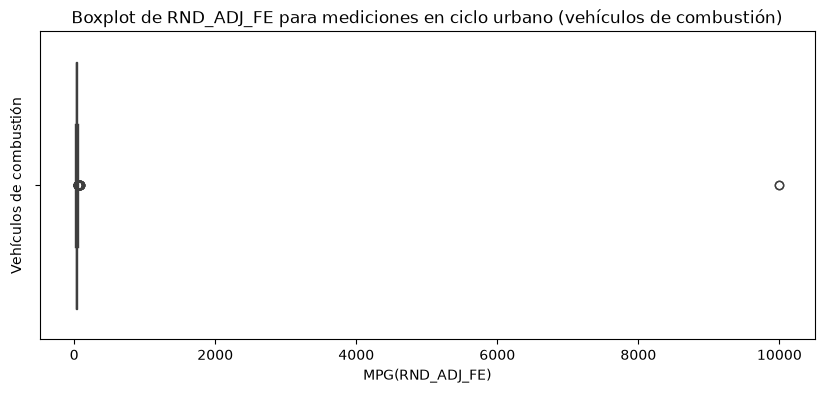

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 4))
sns.boxplot(x=mpg_urbano['RND_ADJ_FE'], orient='h')
plt.title('Boxplot de RND_ADJ_FE para mediciones en ciclo urbano (vehículos de combustión)')
plt.xlabel('MPG(RND_ADJ_FE)')
plt.ylabel("Vehículos de combustión")

plt.show()

#claramente hay  outliers, que son los que superan los 100 mpg.

<Axes: >

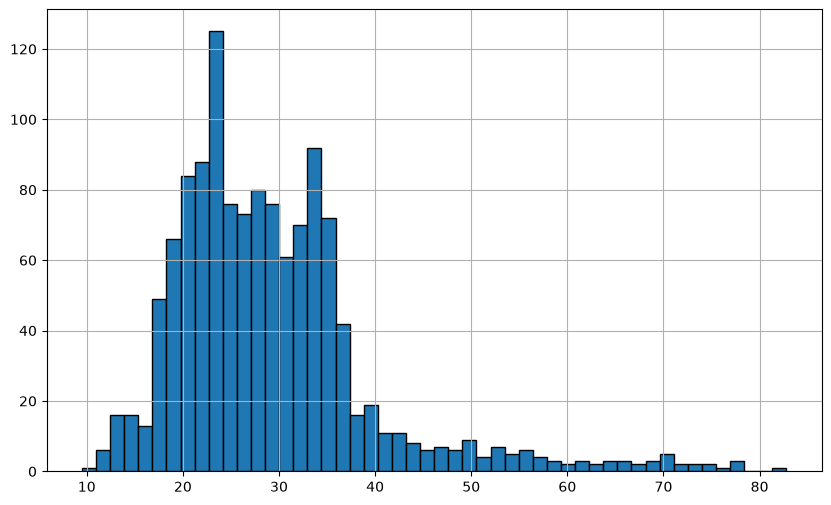

In [27]:
mpg_rango = mpg_urbano[(mpg_urbano['RND_ADJ_FE'] >= 0) & (mpg_urbano['RND_ADJ_FE'] <= 100)]
mpg_rango['RND_ADJ_FE'].hist(bins=50, edgecolor='black', figsize=(10, 6))

In [28]:
mpg_urbano_sin_outliers = mpg_urbano[mpg_urbano['RND_ADJ_FE'] <= 100]

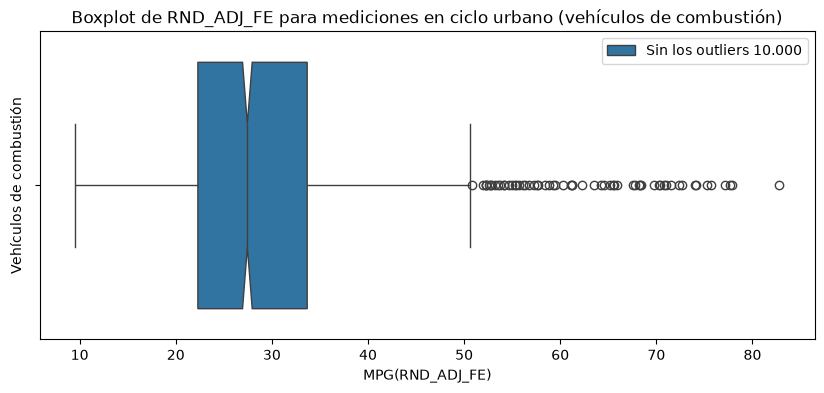

In [30]:


plt.figure(figsize=(10, 4))
sns.boxplot(x=mpg_urbano_sin_outliers['RND_ADJ_FE'], orient='h', notch=True)
plt.title('Boxplot de RND_ADJ_FE para mediciones en ciclo urbano (vehículos de combustión)')
plt.xlabel('MPG(RND_ADJ_FE)')
plt.ylabel("Vehículos de combustión")

plt.legend(['Sin los outliers 10.000'])

plt.show()

In [31]:
cuantil_1 = mpg_urbano['RND_ADJ_FE'].quantile(0.25)
cuantil_3 = mpg_urbano['RND_ADJ_FE'].quantile(0.75)

iqr = cuantil_3 - cuantil_1

limite_inferior = cuantil_1 - 1.5 * iqr
limite_superior = cuantil_3 + 1.5 * iqr

mpg_urbano_sin_outliers = mpg_urbano[(mpg_urbano['RND_ADJ_FE'] >= limite_inferior) & (mpg_urbano['RND_ADJ_FE'] <= limite_superior)]

print(f"El umbral superior estadístico calculado es: {limite_superior:.2f} MPG")
print(mpg_urbano_sin_outliers['RND_ADJ_FE'].describe())

El umbral superior estadístico calculado es: 50.80 MPG
count    1202.000000
mean       27.523877
std         7.446489
min         9.500000
25%        22.100000
50%        26.800000
75%        33.000000
max        50.800000
Name: RND_ADJ_FE, dtype: float64


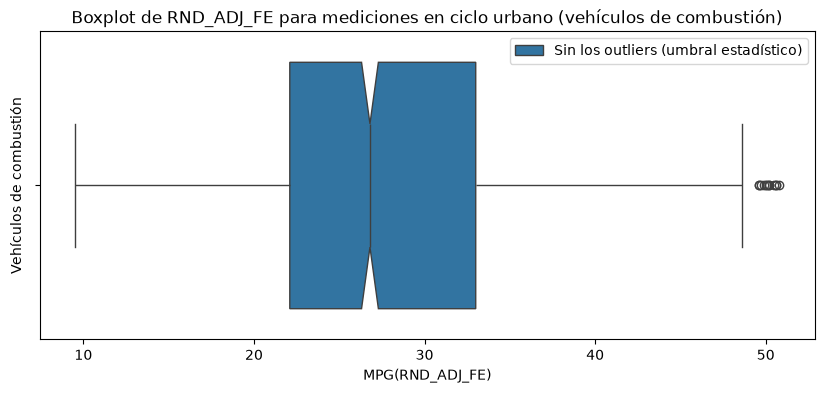

In [33]:

plt.figure(figsize=(10, 4))
sns.boxplot(x=mpg_urbano_sin_outliers['RND_ADJ_FE'], orient='h', notch=True)
plt.title('Boxplot de RND_ADJ_FE para mediciones en ciclo urbano (vehículos de combustión)')
plt.xlabel('MPG(RND_ADJ_FE)')
plt.ylabel("Vehículos de combustión")

plt.legend(['Sin los outliers (umbral estadístico)'])

plt.show()

El valor de la mediana aprox. 26.8 MPG afirmá que, dado que el 50% central de la muestra supera holgadamente la barrera de las 25 MPG, la hipótesis es correcta, la mayoria de las configuraciones de vehiculos a combustion alcanzan al menos 35 pg de economia de combustibl en condiciones de conduccion urbana.